# Week 2 — Food Delivery Exploratory Data Analysis

**Kagnus | Project 2**

This notebook continues the Week 1 cleaned dataset (45,584 rows, 20 fields). We compare operational factors against `Time_taken (min)` using actual calculations, preserve group sizes, and distinguish association from causation. Run from the repository root. In Google Colab, upload the project files into the same folder layout or adjust `DATA_PATH`.

## 1. Load and validate the cleaned data

We check the available columns, data types, and valid delivery durations before computing metrics. Only strictly positive, numeric durations are included in analysis.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

DATA_PATH = Path('data/processed/cleaned_food_delivery.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('../data/processed/cleaned_food_delivery.csv')
assert DATA_PATH.exists(), 'Run from repository root, or upload data/processed/cleaned_food_delivery.csv'
df = pd.read_csv(DATA_PATH)
print('Dataset shape:', df.shape)
print('Columns:', df.columns.tolist())
assert 'Time_taken (min)' in df.columns
df['duration_min'] = pd.to_numeric(df['Time_taken (min)'], errors='coerce')
valid = df.loc[df['duration_min'].gt(0)].copy()
print('Valid duration records:', len(valid), 'Invalid/missing:', len(df)-len(valid))

Dataset shape: (45584, 20)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)']
Valid duration records: 45584 Invalid/missing: 0


## 2. Delivery-duration baseline

Calculate count, mean, median, minimum, maximum, quartiles and standard deviation. Compare mean with median and inspect the distribution for skew or extreme values.

,Metric,Value
0,Count,45584.000
1,Mean (min),26.294
2,Median (min),26.000
3,Minimum (min),10.000
4,Maximum (min),54.000
5,25th percentile (min),19.000
6,75th percentile (min),32.000
7,Std. deviation (min),9.384
8,Skewness,0.486


**Interpretation:** The mean is 26.29 minutes and median 26.00 minutes, with 45,584 valid observations. The observed range is 10–54 minutes; skewness is 0.49. These summarize observed delivery durations, not service-level targets.

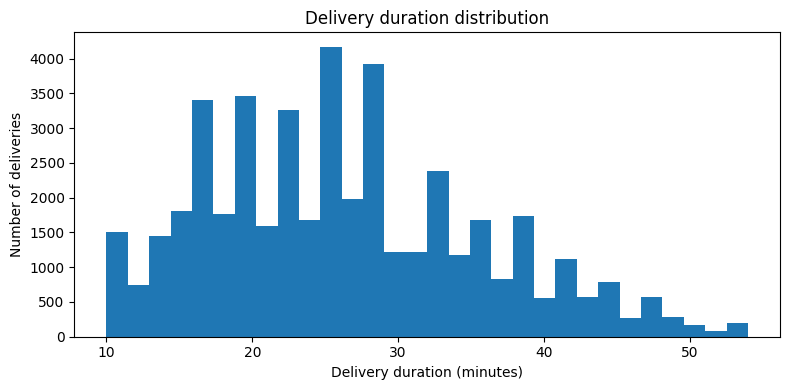

In [2]:
s = valid['duration_min']
baseline = pd.DataFrame({'Metric':['Count','Mean (min)','Median (min)','Minimum (min)','Maximum (min)','25th percentile (min)','75th percentile (min)','Std. deviation (min)','Skewness'], 'Value':[s.count(),s.mean(),s.median(),s.min(),s.max(),s.quantile(.25),s.quantile(.75),s.std(),s.skew()]})
display(baseline.round(3))
display(Markdown(f"**Interpretation:** The mean is {s.mean():.2f} minutes and median {s.median():.2f} minutes, with {s.count():,} valid observations. The observed range is {s.min():.0f}–{s.max():.0f} minutes; skewness is {s.skew():.2f}. These summarize observed delivery durations, not service-level targets."))
fig,ax=plt.subplots(figsize=(8,4));ax.hist(s,bins=30);ax.set(title='Delivery duration distribution',xlabel='Delivery duration (minutes)',ylabel='Number of deliveries');plt.tight_layout();plt.show()

## 3. Traffic, weather, and vehicle comparisons

Each category table reports nonmissing delivery count, mean, and median duration. Category labels are stripped for consistent grouping; missing category labels are shown as `Missing` rather than discarded.

In [3]:
def group_summary(column):
    if column not in valid.columns:
        display(Markdown(f'**Unavailable:** `{column}` is not in this dataset.'))
        return None
    labels=valid[column].astype('string').str.strip().fillna('Missing').replace('', 'Missing')
    out=(valid.assign(category=labels).groupby('category',dropna=False)['duration_min']
         .agg(delivery_count='count',mean_minutes='mean',median_minutes='median')
         .sort_values('mean_minutes',ascending=False))
    return out
summaries={}
for title,col in [('Traffic','Road_traffic_density'),('Weather','Weather_conditions'),('Vehicle type','Type_of_vehicle')]:
    display(Markdown('### '+title))
    result=group_summary(col)
    if result is not None:
        summaries[title]=result
        display(result.round(2))
        high,low=result.iloc[0],result.iloc[-1]
        display(Markdown(f"**Result:** Highest mean is **{result.index[0]}** ({high.mean_minutes:.2f} min, n={int(high.delivery_count):,}); lowest is **{result.index[-1]}** ({low.mean_minutes:.2f} min, n={int(low.delivery_count):,}). Difference: {high.mean_minutes-low.mean_minutes:.2f} min. This comparison does not establish causality."))

### Traffic

,delivery_count,mean_minutes,median_minutes
category,,,
Jam,14139,31.18,31.0
High,4423,27.24,27.0
Medium,10945,26.70,27.0
Missing,601,26.54,26.0
Low,15476,21.27,20.0


**Result:** Highest mean is **Jam** (31.18 min, n=14,139); lowest is **Low** (21.27 min, n=15,476). Difference: 9.91 min. This comparison does not establish causality.

### Weather

,delivery_count,mean_minutes,median_minutes
category,,,
Cloudy,7533,28.92,28.0
Fog,7653,28.91,28.0
Missing,616,26.55,26.0
Windy,7422,26.12,26.0
Sandstorms,7494,25.88,26.0
Stormy,7584,25.87,26.0
Sunny,7282,21.86,20.0


**Result:** Highest mean is **Cloudy** (28.92 min, n=7,533); lowest is **Sunny** (21.86 min, n=7,282). Difference: 7.06 min. This comparison does not establish causality.

### Vehicle type

,delivery_count,mean_minutes,median_minutes
category,,,
motorcycle,26429,27.61,26.0
bicycle,68,26.43,26.0
scooter,15273,24.48,24.0
electric_scooter,3814,24.47,24.0


**Result:** Highest mean is **motorcycle** (27.61 min, n=26,429); lowest is **electric_scooter** (24.47 min, n=3,814). Difference: 3.14 min. This comparison does not establish causality.

## 4. Distance and delivery duration

The dataset provides restaurant and delivery latitude/longitude but no verified road-route distance. We calculate approximate great-circle (straight-line) distance using the haversine formula. Coordinates outside valid ranges or equal to zero are excluded from this calculation. This is not driving distance; possible coordinate anomalies and multiple stops limit interpretation.

Valid coordinate pairs: 41,944; excluded: 3,640
Pearson correlation (straight-line km vs duration min): -0.0029
Distances above 100 km: 431


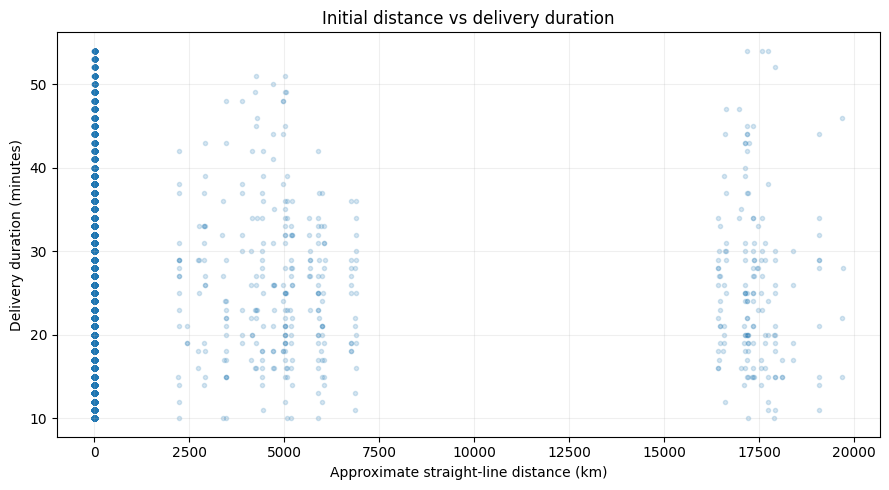

Saved plot: visualizations/initial_distance_vs_duration.png


**Interpretation:** Pearson r = **-0.003** for **41,944** valid coordinate pairs. This is a linear association, not proof of a causal effect. Straight-line distance differs from actual road distance, and extreme coordinate-derived distances may affect the coefficient.

In [4]:
cols=['Restaurant_latitude','Restaurant_longitude','Delivery_location_latitude','Delivery_location_longitude']
for col in cols: valid[col]=pd.to_numeric(valid[col],errors='coerce')
coord_ok=valid[cols].notna().all(axis=1)
for col in ['Restaurant_latitude','Delivery_location_latitude']:
    coord_ok &= valid[col].between(-90,90) & valid[col].ne(0)
for col in ['Restaurant_longitude','Delivery_location_longitude']:
    coord_ok &= valid[col].between(-180,180) & valid[col].ne(0)
dist=valid.loc[coord_ok].copy()
lat1,lon1,lat2,lon2=[np.radians(dist[col].to_numpy()) for col in cols]
a=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
dist['straight_line_km']=6371*2*np.arcsin(np.sqrt(np.clip(a,0,1)))
# Keep all mathematically valid distances; flag extreme distances instead of silently removing them.
r=dist['straight_line_km'].corr(dist['duration_min'])
print(f'Valid coordinate pairs: {len(dist):,}; excluded: {len(valid)-len(dist):,}')
print(f'Pearson correlation (straight-line km vs duration min): {r:.4f}')
print('Distances above 100 km:',int(dist['straight_line_km'].gt(100).sum()))
fig,ax=plt.subplots(figsize=(9,5))
ax.scatter(dist['straight_line_km'],dist['duration_min'],alpha=.18,s=9)
ax.set(title='Initial distance vs delivery duration',xlabel='Approximate straight-line distance (km)',ylabel='Delivery duration (minutes)')
ax.grid(alpha=.2);fig.tight_layout()
out=Path('visualizations/initial_distance_vs_duration.png')
if not out.parent.exists(): out=Path('../visualizations/initial_distance_vs_duration.png')
out.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(out,dpi=160,bbox_inches='tight');plt.show()
print('Saved plot:',out)
display(Markdown(f'**Interpretation:** Pearson r = **{r:.3f}** for **{len(dist):,}** valid coordinate pairs. This is a linear association, not proof of a causal effect. Straight-line distance differs from actual road distance, and extreme coordinate-derived distances may affect the coefficient.'))

## 5. Partner experience and other available factors

The dataset has `Delivery_person_Age` but no clearly documented years-of-experience field. Age is not a valid substitute for experience, so we explicitly mark partner experience as unavailable. We additionally examine multiple deliveries and ratings as associations, while acknowledging incomplete definitions and missing data.

In [5]:
experience=[c for c in df.columns if 'experience' in c.lower()]
print('Documented partner-experience field:', experience if experience else 'Not available — not inferred from age')
for title,col in [('Multiple deliveries','multiple_deliveries'),('Delivery-person ratings','Delivery_person_Ratings')]:
    display(Markdown('### '+title))
    if col not in valid.columns: print('Field unavailable');continue
    if col=='Delivery_person_Ratings':
        vals=pd.to_numeric(valid[col],errors='coerce')
        print('Missing ratings:',int(vals.isna().sum()),'Ratings outside 0–5:',int((vals.notna() & ~vals.between(0,5)).sum()))
        subset=valid.loc[vals.between(0,5)].copy()
        subset['rating_group']=pd.cut(vals.loc[subset.index],bins=[0,3,4,4.5,5],include_lowest=True)
        result=subset.groupby('rating_group',observed=True)['duration_min'].agg(delivery_count='count',mean_minutes='mean',median_minutes='median')
    else:
        result=group_summary(col)
    summaries[title]=result
    display(result.round(2))

Documented partner-experience field: Not available — not inferred from age


### Multiple deliveries

,delivery_count,mean_minutes,median_minutes
category,,,
3.0,361,47.82,48.0
2.0,1985,40.45,40.0
1.0,28151,26.85,26.0
0.0,14094,22.88,22.0
Missing,993,22.77,21.0


### Delivery-person ratings

Missing ratings: 1908 Ratings outside 0–5: 53


,delivery_count,mean_minutes,median_minutes
rating_group,,,
"(-0.001, 3.0]",146,34.22,35.0
"(3.0, 4.0]",2298,36.02,35.0
"(4.0, 4.5]",8919,30.56,32.0
"(4.5, 5.0]",32260,24.38,24.0


## 6. Evidence-based observations

The following statements are generated from the actual calculated tables. Each states a question, metric, result, comparison and sample size. Explanations remain cautious because these are observational data.

In [6]:
observations=[]
for title in ['Traffic','Weather','Vehicle type','Multiple deliveries','Delivery-person ratings']:
    table=summaries.get(title)
    if table is None or len(table)<2:continue
    hi=table.sort_values('mean_minutes',ascending=False).iloc[0]
    lo=table.sort_values('mean_minutes',ascending=False).iloc[-1]
    ix=table.sort_values('mean_minutes',ascending=False).index
    observations.append(f'**{title}: Which group had longer observed delivery durations?** Mean duration was {hi.mean_minutes:.2f} min for {ix[0]} (n={int(hi.delivery_count):,}; median {hi.median_minutes:.2f}) versus {lo.mean_minutes:.2f} min for {ix[-1]} (n={int(lo.delivery_count):,}; median {lo.median_minutes:.2f}), a difference of {hi.mean_minutes-lo.mean_minutes:.2f} min. This association may reflect other operational differences and does not prove causation.')
observations.append(f'**Distance: Is straight-line distance linearly related to duration?** Across {len(dist):,} valid coordinate pairs, Pearson r was {r:.3f}. This describes the observed linear relationship only; routing, traffic and questionable coordinates may affect it.')
for i,obs in enumerate(observations,1):display(Markdown(f'{i}. {obs}'))
assert len(observations)>=5

1. **Traffic: Which group had longer observed delivery durations?** Mean duration was 31.18 min for Jam (n=14,139; median 31.00) versus 21.27 min for Low (n=15,476; median 20.00), a difference of 9.91 min. This association may reflect other operational differences and does not prove causation.

2. **Weather: Which group had longer observed delivery durations?** Mean duration was 28.92 min for Cloudy (n=7,533; median 28.00) versus 21.86 min for Sunny (n=7,282; median 20.00), a difference of 7.06 min. This association may reflect other operational differences and does not prove causation.

3. **Vehicle type: Which group had longer observed delivery durations?** Mean duration was 27.61 min for motorcycle (n=26,429; median 26.00) versus 24.47 min for electric_scooter (n=3,814; median 24.00), a difference of 3.14 min. This association may reflect other operational differences and does not prove causation.

4. **Multiple deliveries: Which group had longer observed delivery durations?** Mean duration was 47.82 min for 3.0 (n=361; median 48.00) versus 22.77 min for Missing (n=993; median 21.00), a difference of 25.05 min. This association may reflect other operational differences and does not prove causation.

5. **Delivery-person ratings: Which group had longer observed delivery durations?** Mean duration was 36.02 min for (3.0, 4.0] (n=2,298; median 35.00) versus 24.38 min for (4.5, 5.0] (n=32,260; median 24.00), a difference of 11.64 min. This association may reflect other operational differences and does not prove causation.

6. **Distance: Is straight-line distance linearly related to duration?** Across 41,944 valid coordinate pairs, Pearson r was -0.003. This describes the observed linear relationship only; routing, traffic and questionable coordinates may affect it.

## 7. Limitations and reproducibility

- The dataset does not document partner years of experience; we do not substitute age.
- Distance is approximate straight-line distance, not actual driving distance.
- Missing category values, unusual coordinates and questionable ratings require caution.
- Observed group differences can be confounded by traffic, location, time and other factors.
- No association is presented as proof of cause and effect.

The notebook uses the existing cleaned dataset from Week 1. The exported scatter plot and this executed notebook form the Week 2 submission. Final charts and recommendations from the earlier complete project remain separate.

In [7]:
assert len(valid)>0 and Path(out).exists();print('Week 2 checks passed:',len(valid),'valid delivery records; scatter plot exported.')

Week 2 checks passed: 45584 valid delivery records; scatter plot exported.
